In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.layers import (
    Input, Conv2D, Dense, Dropout, GlobalAveragePooling2D, RandomRotation
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

C:\Users\Thidar Khaing\.conda\envs\deepenv\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
dataset_dir = "D:/Deep Learning for Image/dataset"

img_height = 224
img_width = 224
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.30,
    subset="training",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="categorical"
)

temp_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.30,
    subset="validation",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="categorical"
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)

Found 1181 files belonging to 5 classes.
Using 827 files for training.
Found 1181 files belonging to 5 classes.
Using 354 files for validation.
Classes: ['bike', 'dogs', 'flowers', 'horses', 'human']
Number of classes: 5


In [3]:
# 15% validation and 15% testing
val_batches = tf.data.experimental.cardinality(temp_ds)

test_ds = temp_ds.take(val_batches // 2)
val_ds = temp_ds.skip(val_batches // 2)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Classes: ['bike', 'dogs', 'flowers', 'horses', 'human']
Number of classes: 5


In [4]:
train_ds = train_ds.map(
    lambda x, y: (preprocess_input(x), y)
)

val_ds = val_ds.map(
    lambda x, y: (preprocess_input(x), y)
)

test_ds = test_ds.map(
    lambda x, y: (preprocess_input(x), y)
)

In [5]:
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 12s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 224, 224, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 224, 224, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 112, 112, 128)       │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 112, 112, 128)       │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 56, 56, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 28, 28, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 28, 28, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 14, 14, 512)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_pool (MaxPooling2D)           │ (None, 7, 7, 512)           │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
#base_model.trainable = True

# Freeze all layers except block5
for layer in base_model.layers:
    if layer.name.startswith('block5'):
        layer.trainable = True
    else:
        layer.trainable = False

In [7]:
for layer in base_model.layers:
    print(layer.name, layer.trainable)

input_layer False
block1_conv1 False
block1_conv2 False
block1_pool False
block2_conv1 False
block2_conv2 False
block2_pool False
block3_conv1 False
block3_conv2 False
block3_conv3 False
block3_pool False
block4_conv1 False
block4_conv2 False
block4_conv3 False
block4_pool False
block5_conv1 True
block5_conv2 True
block5_conv3 True
block5_pool True


In [8]:
inputs = Input(shape=(224, 224, 3))

# VGG16 feature extraction
x = base_model(inputs)

# Classification head
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)

outputs = Dense(5, activation='softmax')(x)

model = Model(inputs, outputs)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 7, 7, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │           1,285 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,847,301 (56.64 MB)

 Trainable params: 7,212,037 (27.51 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [9]:
model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5


C:\Users\Thidar Khaing\.conda\envs\deepenv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


26/26 ━━━━━━━━━━━━━━━━━━━━ 243s 9s/step - accuracy: 0.2914 - loss: 4.7945 - val_accuracy: 0.5370 - val_loss: 1.4174
Epoch 2/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 219s 8s/step - accuracy: 0.5260 - loss: 1.5327 - val_accuracy: 0.7222 - val_loss: 0.7194
Epoch 3/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 231s 9s/step - accuracy: 0.6300 - loss: 1.0606 - val_accuracy: 0.8519 - val_loss: 0.5391
Epoch 4/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 256s 10s/step - accuracy: 0.7461 - loss: 0.7371 - val_accuracy: 0.9136 - val_loss: 0.3251
Epoch 5/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 281s 11s/step - accuracy: 0.8053 - loss: 0.5186 - val_accuracy: 0.9753 - val_loss: 0.1722


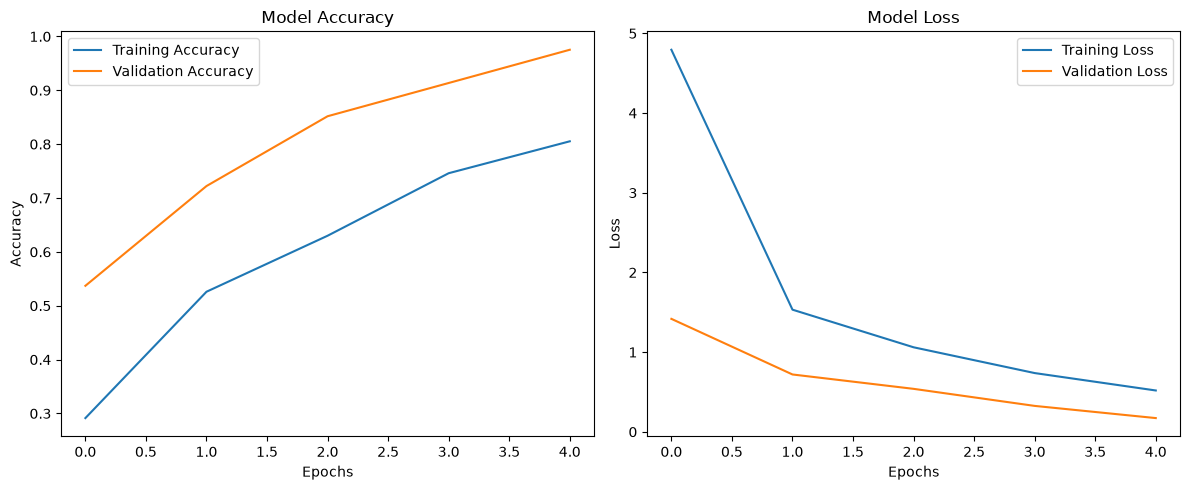

In [10]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

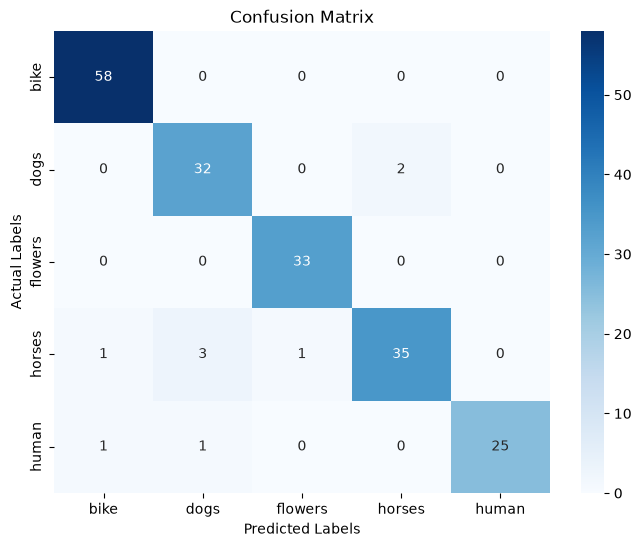

In [11]:
y_true = []
y_pred = []

for images, labels in test_ds:

    # Actual labels
    y_true.extend(np.argmax(labels.numpy(), axis=1))

    # Predicted labels
    predictions = model.predict(images, verbose=0)

    y_pred.extend(np.argmax(predictions, axis=1))

# Convert to NumPy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Labels')
plt.ylabel('Actual Labels')
plt.title('Confusion Matrix')

plt.show()

In [12]:
# Classification Report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

        bike       0.97      1.00      0.98        58
        dogs       0.89      0.94      0.91        34
     flowers       0.97      1.00      0.99        33
      horses       0.95      0.88      0.91        40
       human       1.00      0.93      0.96        27

    accuracy                           0.95       192
   macro avg       0.95      0.95      0.95       192
weighted avg       0.95      0.95      0.95       192



In [18]:
model.save("D:/Deep Learning for Image/models/vgg16_finetune_model.keras")

In [22]:
from tensorflow.keras.models import load_model
# Load trained model
model = load_model(
    "D:/Deep Learning for Image/models/vgg16_finetune_model.keras"
)

# Class names (must follow training dataset order)
class_names = ['bike', 'cars', 'flowers', 'horses', 'human']

# Image path
image_path = "D:/Deep Learning for Image/Test_Images/testimage.jpg"

# Load and resize image
img = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224)
)

# Convert image to array
img_array = tf.keras.utils.img_to_array(img)

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# VGG16 preprocessing
img_array = preprocess_input(img_array)

# Predict
prediction = model.predict(img_array)

# Get predicted class
predicted_index = np.argmax(prediction[0])

predicted_class = class_names[predicted_index]

confidence = prediction[0][predicted_index] * 100

print("Predicted Class:", predicted_class)
print("Confidence: {:.2f}%".format(confidence))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 837ms/step
Predicted Class: cars
Confidence: 97.83%


In [14]:
# Load model, test image, and visualize the image features (or save the feature maps)

In [15]:
#Visualize the image feactures


In [24]:
# Find the VGG16 base model
#base_model = None

for layer in model.layers:
    if isinstance(layer, tf.keras.Model):
        if any(isinstance(l, Conv2D) for l in layer.layers):
            base_model = layer
            break

# Get convolutional layers
if base_model is not None:

    conv_layers = [
        layer for layer in base_model.layers
        if isinstance(layer, Conv2D)
    ]

    feature_extractor = Model(
        inputs=base_model.input,
        outputs=[layer.output for layer in conv_layers]
    )

else:

    conv_layers = [
        layer for layer in model.layers
        if isinstance(layer, Conv2D)
    ]

    feature_extractor = Model(
        inputs=model.input,
        outputs=[layer.output for layer in conv_layers]
    )

print("Number of convolutional layers:", len(conv_layers))

#for layer in conv_layers:
    #print(layer.name)

Number of convolutional layers: 13


In [26]:
# Extract feature maps
feature_maps = feature_extractor.predict(img_array)

print("Number of extracted feature maps:", len(feature_maps))

for layer, fmap in zip(conv_layers, feature_maps):

    print(
        layer.name,
        "Feature map shape:",
        fmap.shape
    )

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 532ms/step
Number of extracted feature maps: 13
block1_conv1 Feature map shape: (1, 224, 224, 64)
block1_conv2 Feature map shape: (1, 224, 224, 64)
block2_conv1 Feature map shape: (1, 112, 112, 128)
block2_conv2 Feature map shape: (1, 112, 112, 128)
block3_conv1 Feature map shape: (1, 56, 56, 256)
block3_conv2 Feature map shape: (1, 56, 56, 256)
block3_conv3 Feature map shape: (1, 56, 56, 256)
block4_conv1 Feature map shape: (1, 28, 28, 512)
block4_conv2 Feature map shape: (1, 28, 28, 512)
block4_conv3 Feature map shape: (1, 28, 28, 512)
block5_conv1 Feature map shape: (1, 14, 14, 512)
block5_conv2 Feature map shape: (1, 14, 14, 512)
block5_conv3 Feature map shape: (1, 14, 14, 512)


In [30]:
import os
import pandas as pd

# Create output folder
output_folder = "D:/Deep Learning for Image/Feature_Maps_2D"

os.makedirs(output_folder, exist_ok=True)

for layer, fmap in zip(conv_layers, feature_maps):

    # Remove batch dimension
    fmap = fmap[0]

    height, width, channels = fmap.shape

    # Reshape: (224, 224, 64) -> (224, 14336)
    fmap_2d = fmap.reshape(height, width * channels)

    # Save as CSV
    csv_path = os.path.join(
        output_folder,
        layer.name + ".csv"
    )

    pd.DataFrame(fmap_2d).to_csv(
        csv_path,
        index=False,
        header=False
    )

    print(
        layer.name,
        "Original:", fmap.shape,
        "Saved:", fmap_2d.shape
    )

block1_conv1 Original: (224, 224, 64) Saved: (224, 14336)
block1_conv2 Original: (224, 224, 64) Saved: (224, 14336)
block2_conv1 Original: (112, 112, 128) Saved: (112, 14336)
block2_conv2 Original: (112, 112, 128) Saved: (112, 14336)
block3_conv1 Original: (56, 56, 256) Saved: (56, 14336)
block3_conv2 Original: (56, 56, 256) Saved: (56, 14336)
block3_conv3 Original: (56, 56, 256) Saved: (56, 14336)
block4_conv1 Original: (28, 28, 512) Saved: (28, 14336)
block4_conv2 Original: (28, 28, 512) Saved: (28, 14336)
block4_conv3 Original: (28, 28, 512) Saved: (28, 14336)
block5_conv1 Original: (14, 14, 512) Saved: (14, 7168)
block5_conv2 Original: (14, 14, 512) Saved: (14, 7168)
block5_conv3 Original: (14, 14, 512) Saved: (14, 7168)


In [31]:
##Visualize the image feactures

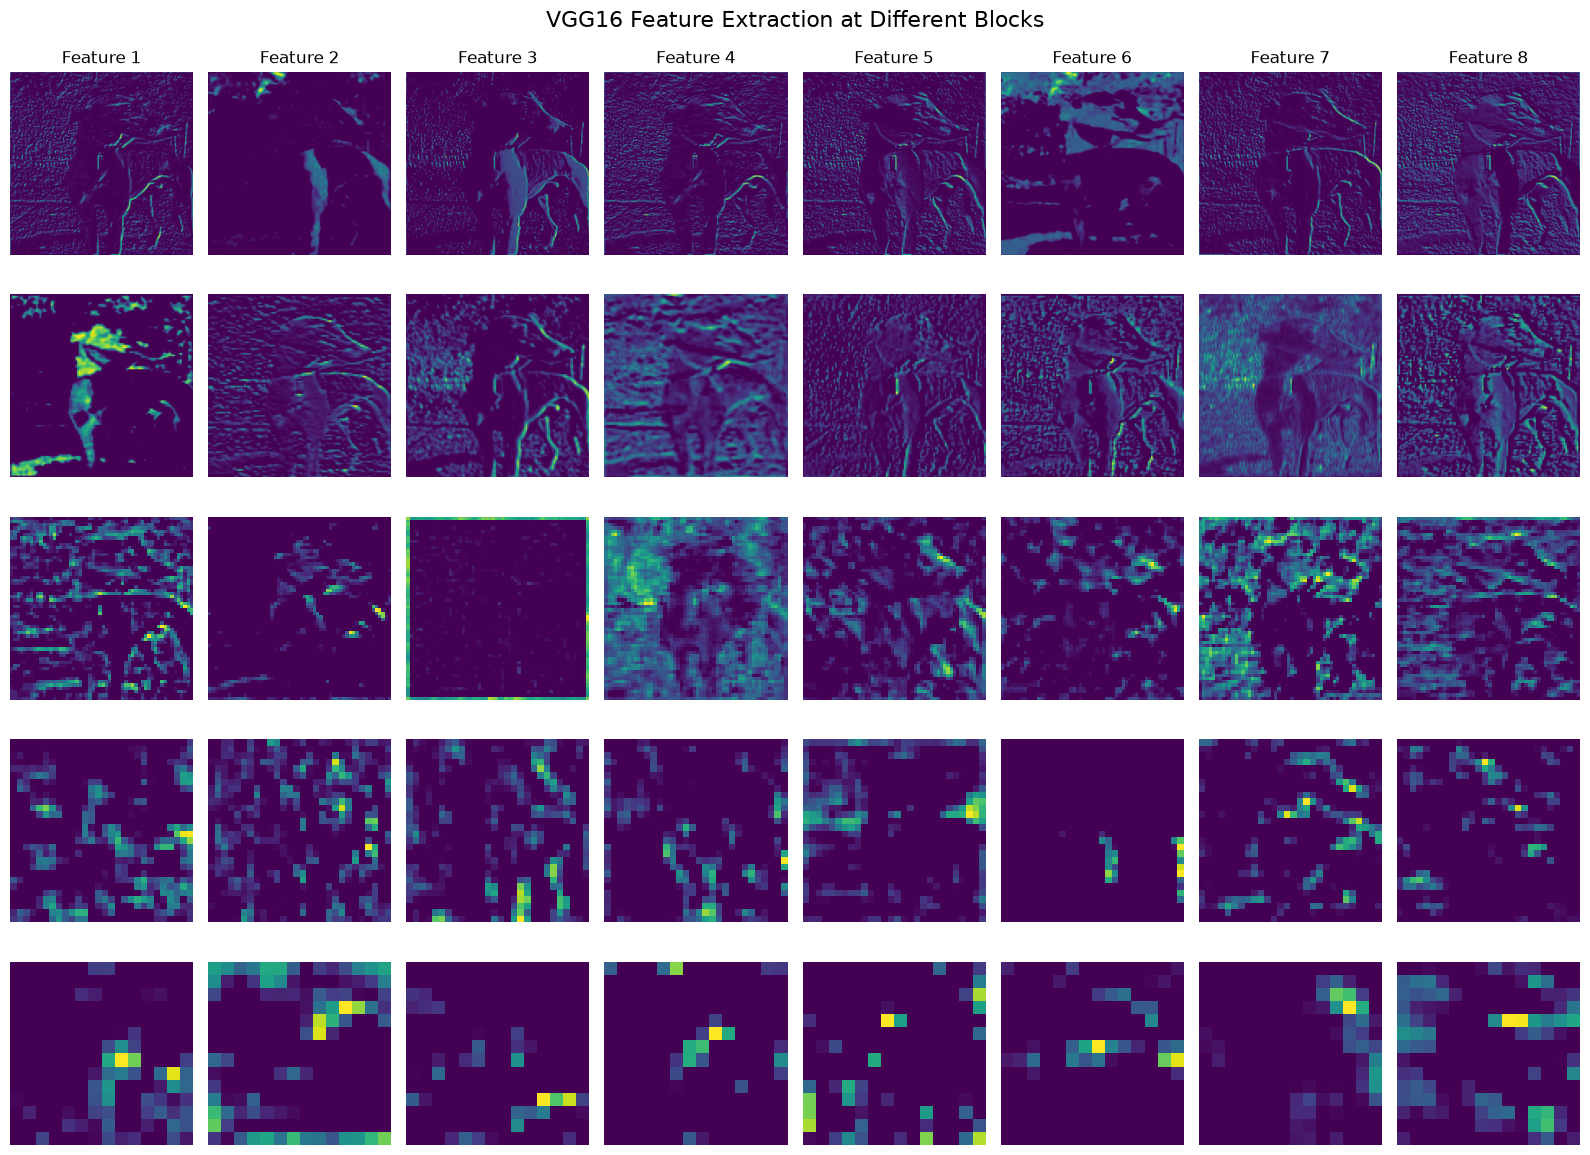

In [32]:
selected_layers = [
    "block1_conv1",
    "block2_conv1",
    "block3_conv1",
    "block4_conv1",
    "block5_conv1"
]

fig, axes = plt.subplots(
    len(selected_layers), 8,
    figsize=(16, 12)
)

for row, layer_name in enumerate(selected_layers):

    # Find corresponding feature map
    layer_index = [
        layer.name for layer in conv_layers
    ].index(layer_name)

    fmap = feature_maps[layer_index][0]

    for col in range(8):

        axes[row, col].imshow(
            fmap[:, :, col],
            cmap='viridis'
        )

        axes[row, col].axis("off")

        if row == 0:
            axes[row, col].set_title(
                f"Feature {col+1}"
            )

    axes[row, 0].set_ylabel(
        layer_name,
        fontsize=11
    )

plt.suptitle(
    "VGG16 Feature Extraction at Different Blocks",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [34]:
### Block 1 – Low-level features
- Edges
- Lines
- Basic_colors
- Simple textures
### Blocks 2 and 3 – Intermediate features
- Textures
- Patterns
- Shapes
- Object parts
### Blocks 4 and 5 – High-level features
- Complex structures
- Object components
- Semantic patterns
- Class-related information

SyntaxError: invalid syntax (3225488633.py, line 5)